<a href="https://colab.research.google.com/github/itznabz/AI/blob/main/FINAL_ASSIGNMENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Healthcare Stroke Prediction – Logistic Regression
**Client:** Nairobi Smart Solutions Ltd | **Unit:** Introduction to Artificial Intelligence

Pipeline: 1) Define goals → 2) Data audit → 3) Collect & prepare → 4) Select & train → 5) Build → 6) Test & present → 7) Evaluate.

## 1. Project Goals
- **Problem:** Identify patients at high risk of stroke from routine health/demographic data.
- **Objective:** Train a Logistic Regression classifier that predicts `stroke` (1 = stroke, 0 = no stroke).
- **Success criteria:** Because only ~5% of patients have a stroke, accuracy is misleading. Targets: **recall (stroke class) ≥ 0.75**, **ROC-AUC ≥ 0.80**, with reasonable precision tradeoff.

**Dataset:** download `healthcare-dataset-stroke-data.csv` from https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset and place it in `data/`.


In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                         	roc_auc_score, RocCurveDisplay, recall_score, precision_score, f1_score, accuracy_score)
import os
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid')


## 2. Data Audit

In [ ]:
import os
from google.colab import files

# Ensure the data directory exists
os.makedirs('data', exist_ok=True)

print("Please upload 'healthcare-dataset-stroke-data.csv'")
uploaded = files.upload()

# Move the uploaded file into the data/ directory
for filename in uploaded.keys():
    os.rename(filename, os.path.join('data', filename))
print("File successfully uploaded and moved to 'data/' directory!")

Please upload 'healthcare-dataset-stroke-data.csv'


In [ ]:
df = pd.read_csv('data/healthcare-dataset-stroke-data.csv')
print(df.shape)
df.head()


In [ ]:
df.info()
df.describe(include='all').T


In [ ]:
# Quality issues
print('Missing values:\n', df.isna().sum(), '\n')
print('Duplicate rows:', df.duplicated().sum())
print('\nClass balance:\n', df['stroke'].value_counts(), '\n', df['stroke'].value_counts(normalize=True).round(4))
for c in ['gender','ever_married','work_type','Residence_type','smoking_status']:
    print('\n', df[c].value_counts())



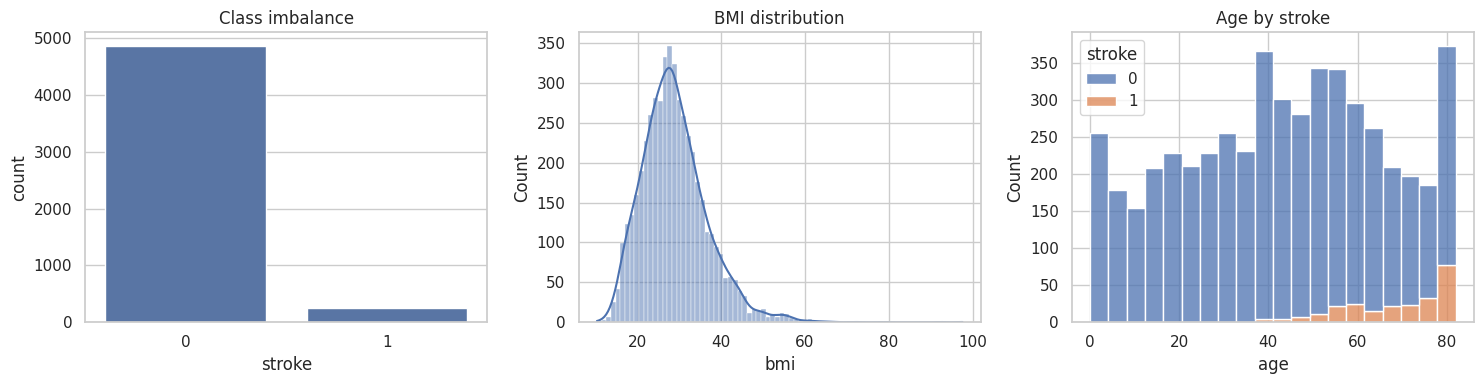

In [ ]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.countplot(x='stroke', data=df, ax=ax[0]); ax[0].set_title('Class imbalance')
sns.histplot(df['bmi'].dropna(), kde=True, ax=ax[1]); ax[1].set_title('BMI distribution')
sns.histplot(data=df, x='age', hue='stroke', multiple='stack', ax=ax[2]); ax[2].set_title('Age by stroke')
plt.tight_layout(); plt.savefig('figures/01_audit.png', dpi=150); plt.show()


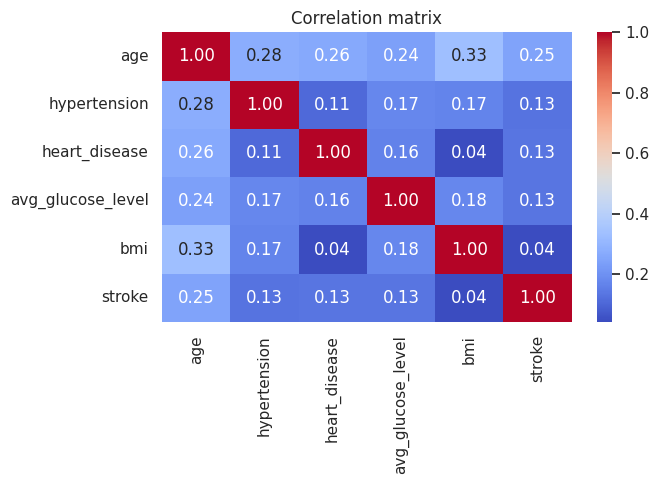

In [ ]:
plt.figure(figsize=(7,5))
sns.heatmap(df.select_dtypes('number').drop(columns='id').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation matrix'); plt.tight_layout(); plt.savefig('figures/02_corr.png', dpi=150); plt.show()



**Audit findings (summarise in report):** missing `bmi`; severe class imbalance; categorical variables needing encoding; `id` is not a predictor; one `Other` gender record; `smoking_status` has an `Unknown` category; skewed `bmi` / `avg_glucose_level` with outliers


## 3. Collect & Prepare Data

In [ ]:
missing_before = df.isna().sum()
data = df.drop(columns='id').copy()
data = data[data['gender'] != 'Other']    	# single record, cannot be learned/stratified
data = data.drop_duplicates()

X = data.drop(columns='stroke'); y = data['stroke']
num_cols = ['age','avg_glucose_level','bmi']
cat_cols = ['gender','hypertension','heart_disease','ever_married','work_type','Residence_type','smoking_status']

# Stratified split FIRST, so imputation/scaling are fitted on training data only (no leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape, y_train.mean().round(4), y_test.mean().round(4))

preprocess = ColumnTransformer([
	('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
	('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)])

# Before / after comparison
Xt = preprocess.fit_transform(X_train)
print('\nMissing BEFORE (full data):\n', missing_before[missing_before>0])
print('Missing AFTER preprocessing (train):', int(np.isnan(Xt).sum()))
print('Feature matrix shape after encoding/scaling:', Xt.shape)


(4087, 10) (1022, 10) 0.0487 0.0489

Missing BEFORE (full data):
 bmi    201
dtype: int64
Missing AFTER preprocessing (train): 0
Feature matrix shape after encoding/scaling: (4087, 15)


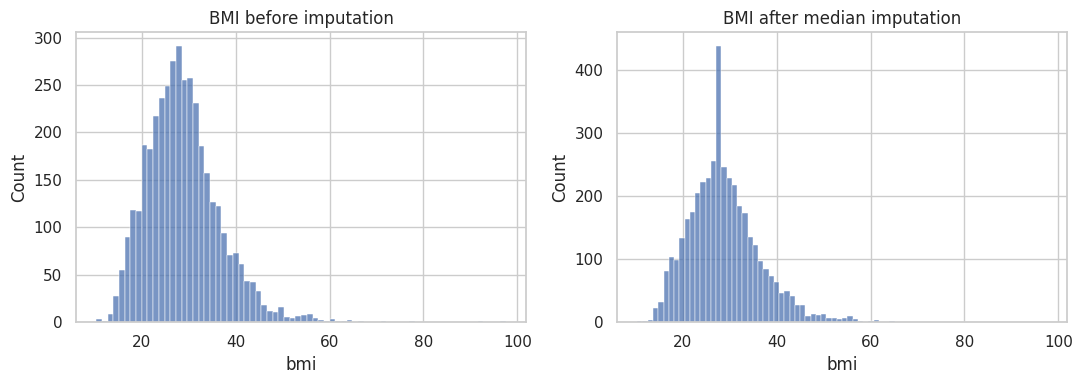

In [ ]:
# Visual: BMI before vs after median imputation
bmi_imp = X_train['bmi'].fillna(X_train['bmi'].median())
fig, ax = plt.subplots(1,2, figsize=(11,4))
sns.histplot(X_train['bmi'].dropna(), ax=ax[0]); ax[0].set_title('BMI before imputation')
sns.histplot(bmi_imp, ax=ax[1]); ax[1].set_title('BMI after median imputation')
plt.tight_layout(); plt.savefig('figures/03_bmi_before_after.png', dpi=150); plt.show()



## 4–5. Select & Train Model (Logistic Regression)
### Baseline model (no imbalance handling)



              precision    recall  f1-score   support

   No stroke       0.95      1.00      0.98       972
      Stroke       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



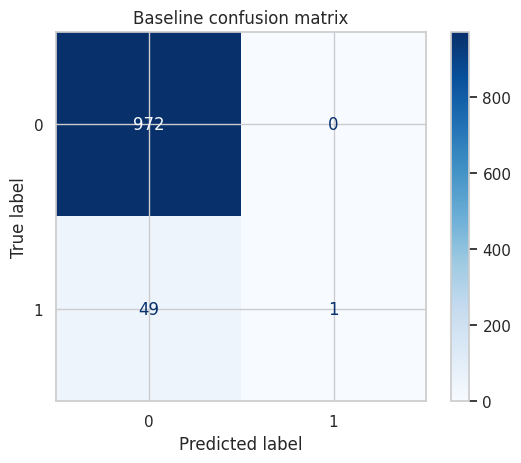

In [ ]:
def evaluate(model, name, threshold=0.5):
	proba = model.predict_proba(X_test)[:,1]
	pred = (proba >= threshold).astype(int)
	res = dict(model=name, accuracy=accuracy_score(y_test,pred), precision=precision_score(y_test,pred,zero_division=0),
               recall=recall_score(y_test,pred), f1=f1_score(y_test,pred), roc_auc=roc_auc_score(y_test,proba))
	print(classification_report(y_test, pred, target_names=['No stroke','Stroke'], zero_division=0))
	return res, pred, proba

baseline = Pipeline([('prep', preprocess), ('clf', LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
res_base, pred_base, proba_base = evaluate(baseline, 'Baseline LR')
ConfusionMatrixDisplay.from_predictions(y_test, pred_base, cmap='Blues'); plt.title('Baseline confusion matrix')
plt.savefig('figures/04_cm_baseline.png', dpi=150); plt.show()



### Refinement 1: handle class imbalance (`class_weight='balanced'`)


              precision    recall  f1-score   support

   No stroke       0.99      0.74      0.84       972
      Stroke       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022



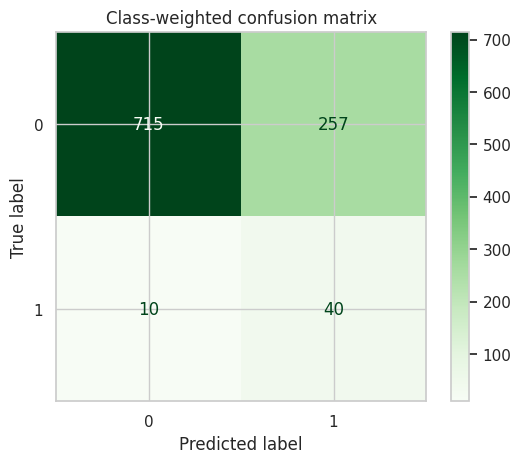

In [ ]:
balanced = Pipeline([('prep', preprocess), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))]).fit(X_train, y_train)
res_bal, pred_bal, proba_bal = evaluate(balanced, 'LR + class_weight')
ConfusionMatrixDisplay.from_predictions(y_test, pred_bal, cmap='Greens'); plt.title('Class-weighted confusion matrix')
plt.savefig('figures/05_cm_balanced.png', dpi=150); plt.show()


### Refinement 2: hyperparameter tuning (GridSearchCV, 5-fold stratified)

In [ ]:
pipe = Pipeline([('prep', preprocess), ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
grid = {'clf__C':[0.01,0.1,1,10,100], 'clf__penalty':['l1','l2'], 'clf__solver':['liblinear']}
gs = GridSearchCV(pipe, grid, scoring='roc_auc', cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1)
gs.fit(X_train, y_train)
print('Best params:', gs.best_params_, '| CV ROC-AUC:', round(gs.best_score_,4))
best = gs.best_estimator_
res_tuned, pred_tuned, proba_tuned = evaluate(best, 'Tuned LR')


Best params: {'clf__C': 0.1, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'} | CV ROC-AUC: 0.8404
              precision    recall  f1-score   support

   No stroke       0.99      0.73      0.84       972
      Stroke       0.13      0.80      0.22        50

    accuracy                           0.73      1022
   macro avg       0.56      0.76      0.53      1022
weighted avg       0.94      0.73      0.81      1022




## 6. Test & Present Results


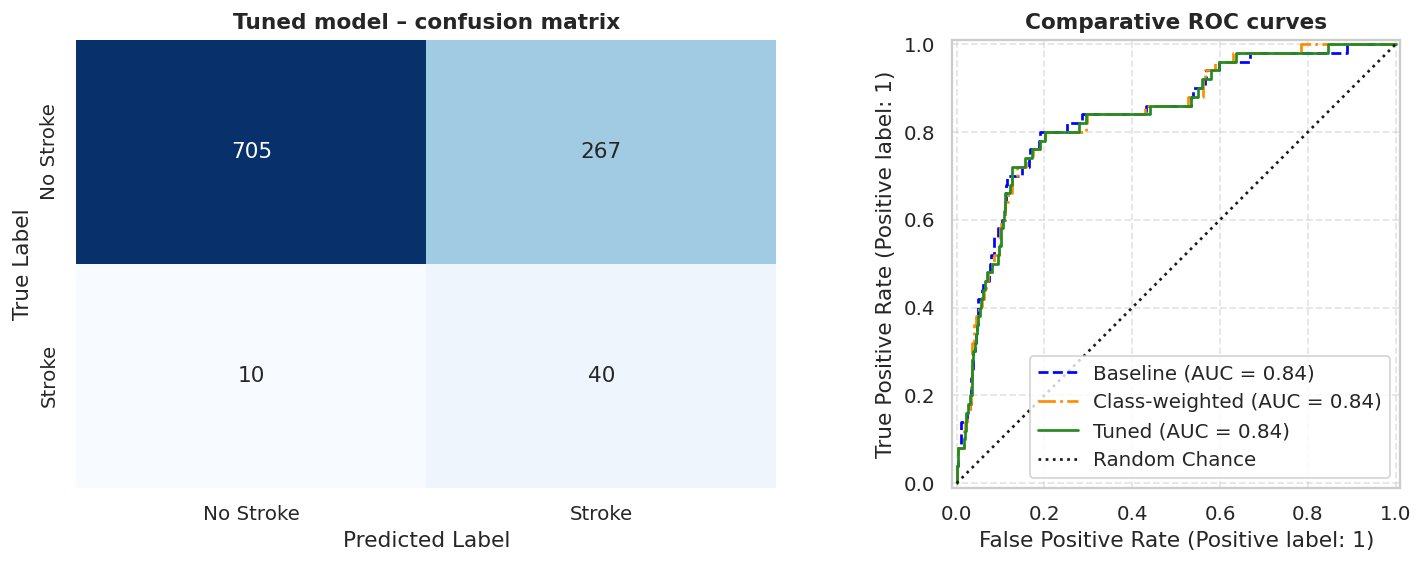

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), dpi=130)

#Cleaner Confusion Matrix (Blues heatmap style)
cm = confusion_matrix(y_test, pred_tuned)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0],
            xticklabels=['No Stroke', 'Stroke'], yticklabels=['No Stroke', 'Stroke'])
ax[0].set_title('Tuned model – confusion matrix', fontweight='bold')
ax[0].set_xlabel('Predicted Label')
ax[0].set_ylabel('True Label')

#Styled ROC Curves
for m, n, ls, col in zip([baseline, balanced, best], ['Baseline', 'Class-weighted', 'Tuned'], ['--', '-.', '-'], ['blue', 'darkorange', 'forestgreen']):
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=n, ax=ax[1], linestyle=ls, color=col)

ax[1].plot([0, 1], [0, 1], 'k:', label='Random Chance')
ax[1].set_title('Comparative ROC curves', fontweight='bold')
ax[1].legend(loc='lower right', frameon=True)
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/06_final_eval.png', dpi=150)
plt.show()

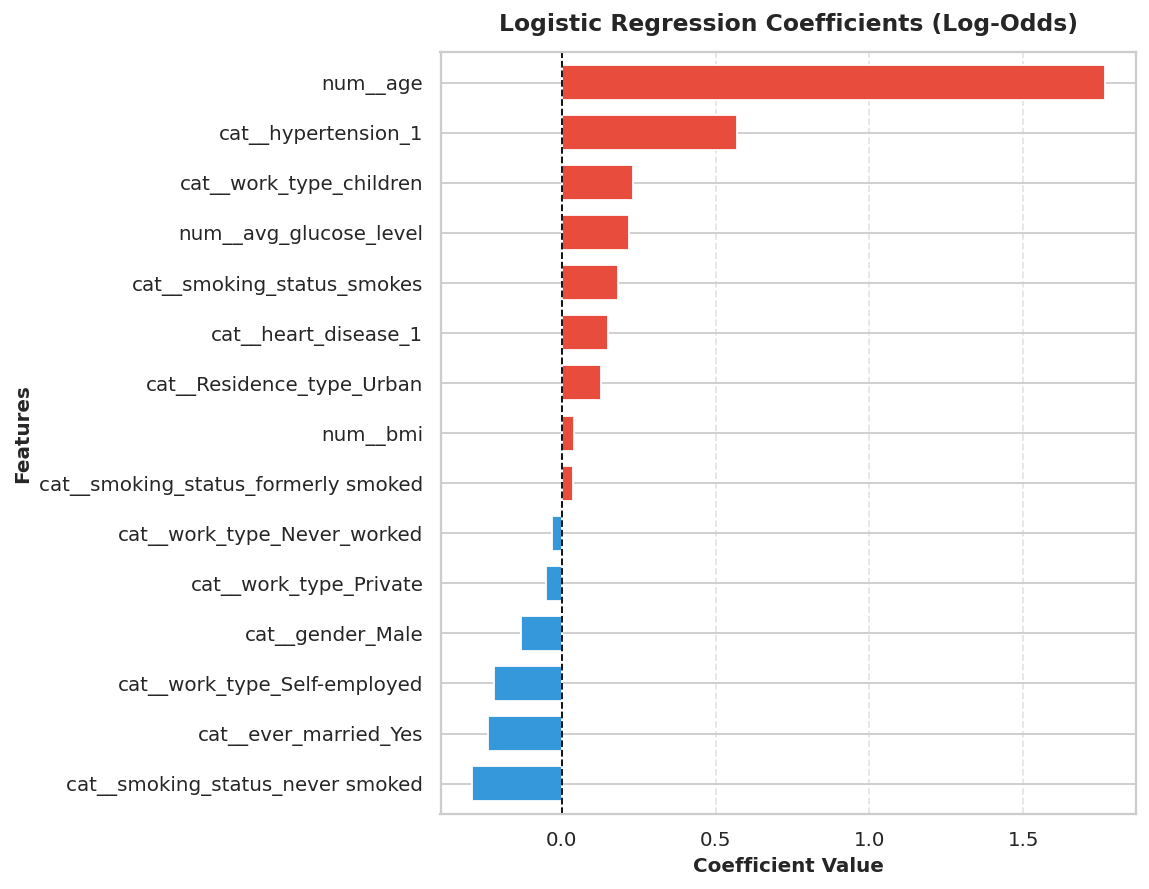

,coef,odds_ratio
num__age,1.764,5.833
cat__hypertension_1,0.570,1.768
cat__work_type_children,0.230,1.259
num__avg_glucose_level,0.218,1.243
cat__smoking_status_smokes,0.183,1.200
cat__heart_disease_1,0.150,1.162
cat__Residence_type_Urban,0.129,1.138
num__bmi,0.042,1.043
cat__smoking_status_formerly smoked,0.036,1.036
cat__work_type_Never_worked,-0.032,0.969


In [ ]:
names = best.named_steps['prep'].get_feature_names_out()
coef = pd.Series(best.named_steps['clf'].coef_[0], index=names).sort_values()

plt.figure(figsize=(9, 7), dpi=130)
coef.plot.barh(color=np.where(coef > 0, '#E74C3C', '#3498DB'), width=0.7)
plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.title('Logistic Regression Coefficients (Log-Odds)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Coefficient Value', fontsize=11, fontweight='bold')
plt.ylabel('Features', fontsize=11, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/07_coefficients.png', dpi=150)
plt.show()

# Display odds ratios dataframe
display(pd.DataFrame({'coef': coef, 'odds_ratio': np.exp(coef)}).round(3).sort_values('odds_ratio', ascending=False).head(10))

In [ ]:
# Demo: predict for a new patient
new = pd.DataFrame([{'gender':'Male','age':72,'hypertension':1,'heart_disease':1,'ever_married':'Yes','work_type':'Private',
                 	'Residence_type':'Urban','avg_glucose_level':190.0,'bmi':31.0,'smoking_status':'formerly smoked'}])
p = best.predict_proba(new)[0,1]
print(f'Predicted stroke probability: {p:.2%} ->', 'HIGH RISK' if p>=0.5 else 'low risk')


Predicted stroke probability: 90.00% -> HIGH RISK


## 7. Evaluate & Improvements
Compare the three models in `results_summary.csv`. Discussion points (expand in the report): recall vs precision tradeoff in a screening context; limitations (few positive cases, median imputation, no external validation, linear assumptions); improvements: SMOTE/under-sampling, threshold tuning, regression-based BMI imputation, feature interactions (age×hypertension), tree ensembles for comparison, SHAP explanations, more data.
